# SMILE-2+ の検出器と座標系

チュートリアルを始める前に、SMILE-2+ の検出器の構成、ETCC で測る量、**座標系の定義**をまとめます。
以降のノートブックの座標(`Pe`, `Pg`, `Track_Min` など)はすべてここで定義する座標系です。

## 1. ETCC(電子飛跡検出型コンプトンカメラ)

入射ガンマ線が TPC のガスの中でコンプトン散乱し、

- **反跳電子**の飛跡とエネルギー $K_e$ を **ガス TPC**(電子飛跡検出器)で、
- **散乱ガンマ線**の吸収位置とエネルギー $E_g$ を、TPC を囲む**シンチレータ(HA)**で

測ります。入射エネルギーは $E_0 = E_g + K_e$ です。

| 量 | 意味 |
|---|---|
| 散乱角 $\phi$ | 入射ガンマ線と散乱ガンマ線のなす角。$\cos\phi = 1 - m_ec^2\left(\frac{1}{E_g} - \frac{1}{E_g + K_e}\right)$ |
| $\alpha$ | 散乱ガンマ線と反跳電子のなす角。エネルギーから求めた値(`alpha_kin`)と飛跡から求めた値を比べるとイベント選択に使える |
| event circle | 散乱ガンマ線の向きと $\phi$ だけからは、到来方向は円錐(天球上の円)までしか決まらない |
| ARM | 円の半径方向の分解能(角度分解能 Angular Resolution Measure)。主にエネルギー分解能で決まる |
| SPD | 円の周方向の分解能(Scatter Plane Deviation)。**電子の向きを測るので円の上の 1 点に絞れる** — 電子飛跡を測る ETCC の特徴 |

## 2. SMILE-2+ の構成

| 部分 | 中身 |
|---|---|
| TPC(電子飛跡検出器) | 約 30 cm 角、Ar ベースのガス 2 気圧(Ar : CF$_4$ : iC$_4$H$_{10}$ = 95 : 3 : 2)。読み出しは μ-PIC と GEM |
| μ-PIC のストリップ | アノード 384 本(X 方向の位置)、カソード 384 本(Y 方向の位置)、ピッチ 0.8 mm(3 ボード × 128 本) |
| ドリフト方向 | 電子は Z 方向に GEM・μ-PIC へドリフトし、到着時刻(クロック 10 ns)から Z を求める |
| シンチレータ(HA) | 18 モジュール。底面に 6 台、側面 4 面に 3 台ずつ。各モジュールは PMT 6 本、各 PMT の前に 8 × 8 ピクセルの結晶(ピッチ 6 mm) |

## 3. 座標系

| | 定義 |
|---|---|
| 原点 | **μ-PIC の中央** |
| X 軸 | **アノード**のストリップ番号が増える方向。$x = 0.8\,(\mathrm{strip} - 191.5)$ mm |
| Y 軸 | **カソード**のストリップ番号が増える方向。$y = 0.8\,(\mathrm{strip} - 191.5)$ mm |
| Z 軸 | **下向き**(μ-PIC からドリフト領域・底面のシンチの方へ)。$z = v_{\rm drift}\,(\mathrm{clock} - \mathrm{offset}) + 27$ mm |

- Z の式の `offset` と 27 mm は、**クロックを μ-PIC からの距離に直すための補正**です。
  - クロックは読み出しの時間窓(1024 クロック = 10.24 μs)の中での時刻なので、まず `offset`(電子が GEM に着いた
    = ドリフト距離 0 にあたるクロック)を引いてドリフト時間にし、ドリフト速度 $v_{\rm drift}$(約 0.38 mm/clock)を掛けて
    **GEM からの距離**にします。
  - 電子の増幅は GEM に着いた時点で始まるので、そこに μ-PIC から GEM までの距離 **27 mm** を足して、**μ-PIC(原点)からの距離** にします。
  - `offset` と $v_{\rm drift}$ は `drift_velocity.dat` から読みます(1 行目が `offset`、以降が時刻ごとの $v_{\rm drift}$)。
    27 mm(GEM の位置)はコードに固定値で書かれています。詳しくは 6_TOT_Skewness。
- ドリフト領域はおよそ $z = 27$〜$330$ mm。
- 線源は検出器の**上方**($z < 0$)にあり、ガンマ線は $+z$ 方向(下向き)に入射します。
- 単位はすべて mm、エネルギーは keV です。

## 4. このチュートリアルで使うデータ

2019/07/01 の地上較正の測定です。**Cs-137(662 keV)の線源を、検出器の真上 $(x, y, z) = (0, 0, -1626)$ mm に 1 か所**置いて測りました。
期間ごとに `20190701_Per02`, `20190701_Per03` などに分かれていて、チュートリアルでは主に Per02 を使います。

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials_caldata" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データの準備

データ(20190701 の較正データ **Per02**)の入手方法と置き場所は、
**[1_DataIO のノートブック](../1_DataIO/DataIO_example.ipynb) の「1. データの準備」**を見てください。
NAS を読める計算機では、ここでは何もする必要はありません。

下のセルで、設定ファイル `config/smile2p_20190701_Per02.json` が指すデータが見つかるかだけ確認します
(`MISSING` と出たら 1_DataIO の 1 節を見てください)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/sm2+_cal_rawdata/20190701_Per02
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/param/20190528


## 5. 検出器の配置を描く

シンチの各モジュールの位置と向きは `param/20190528/HAs.pos` に書かれています(1 行 = 1 モジュール:
番号、中心 $(x, y, z)$、モジュール面内の 2 方向の向き)。HA_Calc はこれを使ってピクセルの位置 `Pg` を計算します:

$$\vec P_g = \vec c + h_x\,\vec d_x + h_y\,\vec d_y,\qquad
h_x = 54\,(\mathrm{pmt}\bmod 2 - 0.5) + 6\,(x_{\rm id} - 3.5),\quad
h_y = 54\,(1 - \lfloor \mathrm{pmt}/2 \rfloor) + 6\,(y_{\rm id} - 3.5)$$

($\vec d_x = (d_{xx}, d_{yx}, d_{zx})$, $\vec d_y = (d_{xy}, d_{yy}, d_{zy})$)。全ピクセル(18 × 6 × 64)の中心と TPC の範囲を描きます。

In [3]:
rows = [l.split() for l in (Path(cfg["parameters"]["HA_Calc"]["parameter_dir"]) / "HAs.pos").read_text().splitlines() if l.strip()]
pix = []   # (HA 番号, x, y, z)
for r in rows:
    ha = int(r[0]); c = np.array(r[1:4], float)
    dxx, dxy, dyx, dyy, dzx, dzy = map(float, r[4:10])
    dx, dy = np.array([dxx, dyx, dzx]), np.array([dxy, dyy, dzy])
    for pmt in range(6):
        for xi in range(8):
            for yi in range(8):
                hx = 54 * (pmt % 2 - 0.5) + 6 * (xi - 3.5)
                hy = 54 * (1 - pmt // 2) + 6 * (yi - 3.5)
                pix.append([ha, *(c + hx * dx + hy * dy)])
pix = np.array(pix)
bottom = pix[:, 3] > 300
print("pixels:", len(pix), " bottom:", bottom.sum(), " side:", (~bottom).sum())

pixels: 6912  bottom: 2496  side: 4416


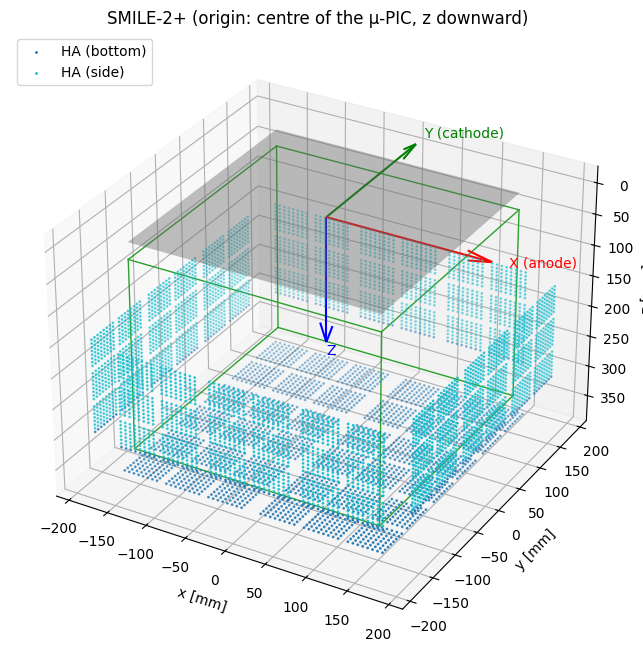

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
TPC = dict(x=(-153.6, 153.6), y=(-153.6, 153.6), z=(27.0, 332.0))   # ドリフト領域(有効体積の外枠)

def box_edges(ax, x, y, z, **kw):
    for xs, ys, zs in [((x[0], x[1]), (y[0], y[0]), (z[0], z[0])), ((x[0], x[1]), (y[1], y[1]), (z[0], z[0])),
                       ((x[0], x[1]), (y[0], y[0]), (z[1], z[1])), ((x[0], x[1]), (y[1], y[1]), (z[1], z[1])),
                       ((x[0], x[0]), (y[0], y[1]), (z[0], z[0])), ((x[1], x[1]), (y[0], y[1]), (z[0], z[0])),
                       ((x[0], x[0]), (y[0], y[1]), (z[1], z[1])), ((x[1], x[1]), (y[0], y[1]), (z[1], z[1])),
                       ((x[0], x[0]), (y[0], y[0]), z), ((x[1], x[1]), (y[0], y[0]), z),
                       ((x[0], x[0]), (y[1], y[1]), z), ((x[1], x[1]), (y[1], y[1]), z)]:
        ax.plot(xs, ys, zs, **kw)

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(projection="3d")
ax.scatter(*pix[bottom, 1:].T, s=1, c="tab:blue", label="HA (bottom)")
ax.scatter(*pix[~bottom, 1:].T, s=1, c="tab:cyan", label="HA (side)")
box_edges(ax, **TPC, color="tab:green", lw=1)
xx, yy = np.meshgrid([-153.6, 153.6], [-153.6, 153.6])
ax.plot_surface(xx, yy, np.zeros_like(xx), color="gray", alpha=0.4)          # μ-PIC (z = 0)
for v, lab, col in [((200, 0, 0), "X (anode)", "r"), ((0, 200, 0), "Y (cathode)", "g"), ((0, 0, 200), "Z", "b")]:
    ax.quiver(0, 0, 0, *v, color=col, arrow_length_ratio=0.15); ax.text(*(1.1 * np.array(v)), lab, color=col)
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.set_zlabel("z [mm]")
ax.invert_zaxis()   # z は下向き
ax.set_title("SMILE-2+ (origin: centre of the μ-PIC, z downward)"); ax.legend(loc="upper left")
plt.show()

上から見た図(x-y)と横から見た図(x-z)です。灰色の線が μ-PIC($z = 0$)、緑の枠が TPC のドリフト領域、
赤い矢印が線源の方向($z = -1626$ mm、図の外)です。

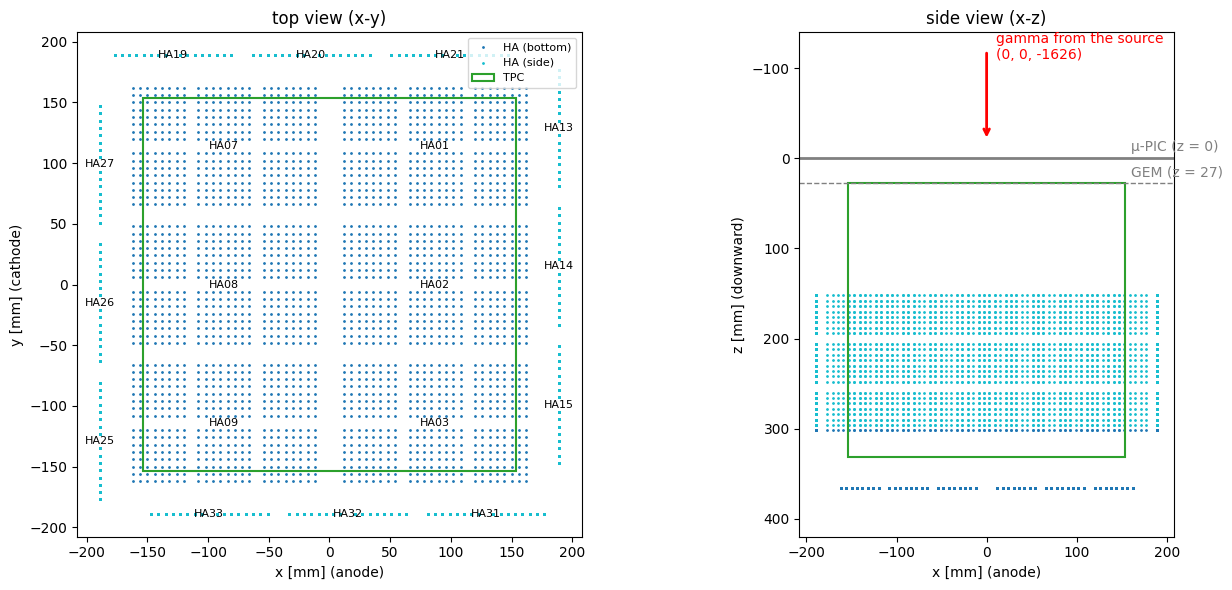

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].scatter(pix[bottom, 1], pix[bottom, 2], s=1, c="tab:blue", label="HA (bottom)")
ax[0].scatter(pix[~bottom, 1], pix[~bottom, 2], s=1, c="tab:cyan", label="HA (side)")
ax[0].add_patch(plt.Rectangle((-153.6, -153.6), 307.2, 307.2, fill=False, ec="tab:green", lw=1.5, label="TPC"))
for r in rows:
    ax[0].text(float(r[1]), float(r[2]), f"HA{int(r[0]):02d}", fontsize=8, ha="center", va="center")
ax[0].set_xlabel("x [mm] (anode)"); ax[0].set_ylabel("y [mm] (cathode)"); ax[0].set_title("top view (x-y)")
ax[0].set_aspect("equal"); ax[0].legend(loc="upper right", fontsize=8)

ax[1].scatter(pix[bottom, 1], pix[bottom, 3], s=1, c="tab:blue")
ax[1].scatter(pix[~bottom, 1], pix[~bottom, 3], s=1, c="tab:cyan")
ax[1].add_patch(plt.Rectangle((-153.6, 27), 307.2, 305, fill=False, ec="tab:green", lw=1.5))
ax[1].axhline(0, color="gray", lw=2); ax[1].text(160, -8, "μ-PIC (z = 0)", color="gray")
ax[1].axhline(27, color="gray", lw=1, ls="--"); ax[1].text(160, 20, "GEM (z = 27)", color="gray")
ax[1].annotate("", xy=(0, -20), xytext=(0, -120), arrowprops=dict(arrowstyle="->", color="r", lw=2))
ax[1].text(10, -110, "gamma from the source\n(0, 0, -1626)", color="r")
ax[1].set_ylim(420, -140)   # z は下向き
ax[1].set_xlabel("x [mm] (anode)"); ax[1].set_ylabel("z [mm] (downward)"); ax[1].set_title("side view (x-z)")
ax[1].set_aspect("equal")
fig.tight_layout(); plt.show()

## 次へ

- データの入手と再構成: `../1_DataIO/`